# VAE with a ResNet-18 encoder on MVTec bottles

I trained a VAE with a frozen pretrained ResNet-18 encoder and my own upsampling decoder on defect-free bottle images from MVTec AD, with a warm-up for the KL weight. The plan is to use reconstruction error for anomaly detection. For now it only compares the reconstruction error of a train image and a test image. Training was stopped early.

In [1]:
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from datasets import load_dataset
from PIL import Image
import io

dataset_train = load_dataset("TheoM55/mvtec_all_objects_split", split="bottle.train")
dataset_test = load_dataset("TheoM55/mvtec_all_objects_split", split="bottle.test")

README.md:   0%|          | 0.00/4.32k [00:00<?, ?B/s]

data/bottle.train-00000-of-00001.parquet:   0%|          | 0.00/112M [00:00<?, ?B/s]

data/bottle.test-00000-of-00001.parquet:   0%|          | 0.00/44.6M [00:00<?, ?B/s]

data/cable.train-00000-of-00001.parquet:   0%|          | 0.00/303M [00:00<?, ?B/s]

Generating tile.train split:   0%|          | 0/230 [00:00<?, ? examples/s]

Generating tile.test split:   0%|          | 0/117 [00:00<?, ? examples/s]

... (4 outputs left out)

Generating wood.train split:   0%|          | 0/247 [00:00<?, ? examples/s]

Generating wood.test split:   0%|          | 0/79 [00:00<?, ? examples/s]

Generating zipper.train split:   0%|          | 0/240 [00:00<?, ? examples/s]

Generating zipper.test split:   0%|          | 0/151 [00:00<?, ? examples/s]

In [2]:
import torchvision.models as models
import torch.nn as nn
import torchvision.transforms.v2 as v2

# The modern PyTorch way to load pre-trained weights
weights = models.ResNet18_Weights.DEFAULT
enc_resnet = models.resnet18(weights=weights)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 195MB/s]


In [3]:
class CustDataset(Dataset):
  def __init__(self, dataset, size_ = 256):
    self.dataset = dataset
    self.transform = v2.Compose([
        v2.ToTensor(),
        v2.Resize((size_, size_)),
    ])

  def __len__(self):
    return len(self.dataset)

  def __getitem__(self, idx):
    img_path = self.dataset[idx]['image_path']
    img = self.transform(img_path)
    return img

In [4]:
from torch.utils.data import DataLoader
train = CustDataset(dataset_train)
test = CustDataset(dataset_test)
train_loader = DataLoader(train, batch_size = 8, shuffle = True)
test_loader = DataLoader(test, batch_size = 1, shuffle = True)

/usr/local/lib/python3.12/dist-packages/torchvision/transforms/v2/_deprecated.py:42: UserWarning: The transform `ToTensor()` is deprecated and will be removed in a future release. Instead, please use `v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])`.Output is equivalent up to float precision.
  warnings.warn(


In [5]:
class ResNet18VAE(nn.Module):
    def __init__(
        self,
        enc_resnet,
        latent_channels: int = 32,
        pretrained_encoder: bool = True,
        img_channels: int = 3
    ):
        super().__init__()
        self.encoder = ResNet18Encoder(enc_resnet)
        self.to_mu = nn.Conv2d(512, latent_channels, kernel_size=1)
        self.to_logvar = nn.Conv2d(512, latent_channels, kernel_size=1)
        self.decoder = ResNet18Decoder(latent_channels, out_channels=img_channels)
        self.latent_channels = latent_channels

    def reparametrize(self, mu, logvar):
      std = torch.exp(0.5 * logvar)
      epsilon = torch.randn_like(std)
      return mu + std * epsilon

    def forward(self, x: torch.Tensor):
      x = self.encoder(x)
      mu = self.to_mu(x)
      logvar = self.to_logvar(x)
      logvar = torch.clamp(logvar, min=-3.0, max=3.0) # for numerical stability not -10, 10 as wouild overshoot, even during training
      z = self.reparametrize(mu, logvar) if self.training else mu
      x_hat = self.decoder(z)
      return x_hat, mu, logvar

    @torch.no_grad()
    def sample_reconstructions(self, x: torch.Tensor, n_samples: int = 8):
        """Draw multiple z ~ q(z|x) and decode each -- used for the
        'reconstruction probability' anomaly score (An & Cho, 2015)."""
        feat = self.encoder(x)
        mu = self.to_mu(feat)
        logvar = torch.clamp(self.to_logvar(feat), -10.0, 10.0)
        recons = []
        for _ in range(n_samples):
            z = self.reparameterize(mu, logvar)
            recons.append(self.decoder(z))
        return torch.stack(recons, dim=0), mu, logvar  # (n_samples, B, C, H, W)

In [58]:
import torch.nn.functional as F
class ResNet18Encoder(nn.Module):
  def __init__(self, resnet, latent_dim = 512):
    super(ResNet18Encoder, self).__init__()
    self.resnet = resnet
    self.latent_dim = latent_dim
    self.stem = nn.Sequential(
            self.resnet.conv1,
            self.resnet.bn1,
            self.resnet.relu,
            self.resnet.maxpool,
        )
    self.layer1 = self.resnet.layer1  # /4
    self.layer2 = self.resnet.layer2  # /8
    self.layer3 = self.resnet.layer3  # /16
    self.layer4 = self.resnet.layer4  # /32

  def forward(self, x):
      x = self.stem(x)
      x = self.layer1(x)
      x = self.layer2(x)
      x = self.layer3(x)
      x = self.layer4(x)
      return x  # (B, 512, H/32, W/32) so (B, 512, 8, 8)


class DecoderBlock(nn.Module):

    def __init__(self, in_ch: int, out_ch: int):
        super().__init__()
        self.up = nn.ConvTranspose2d(in_ch, out_ch, kernel_size=4, stride=2, padding=1)
        self.bn1 = nn.BatchNorm2d(out_ch)
        self.conv = nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(out_ch)
        self.act = nn.ReLU(inplace=True)

    def forward(self, x):
        x = self.act(self.bn1(self.up(x)))
        x = self.act(self.bn2(self.conv(x)))
        return x

class ResNet18Decoder(nn.Module):

    def __init__(self, latent_channels: int, out_channels: int = 3):
        super().__init__()
        self.in_conv = nn.Sequential(
            nn.Conv2d(latent_channels, 512, kernel_size=3, padding=1),
            nn.BatchNorm2d(512),
            nn.ReLU(inplace=True),
        )
        self.up1 = DecoderBlock(512, 256)  # 8   -> 16
        self.up2 = DecoderBlock(256, 128)  # 16  -> 32
        self.up3 = DecoderBlock(128, 64)   # 32  -> 64
        self.up4 = DecoderBlock(64, 64)    # 64  -> 128
        self.up5 = DecoderBlock(64, 32)    # 128 -> 256
        self.out_conv = nn.Conv2d(32, out_channels, kernel_size=3, padding=1)

    def forward(self, z):
        x = self.in_conv(z)
        x = self.up1(x)
        x = self.up2(x)
        x = self.up3(x)
        x = self.up4(x)
        x = self.up5(x)
        x = self.out_conv(x)
        return x


def vae_loss(x_hat: torch.Tensor, x_orig: torch.Tensor, mu: torch.Tensor,
             logvar: torch.Tensor, beta: float = 0.03):
  # Outputs: [Batch, Channel, Height, Width]
  #squared_error = F.mse_loss(x_hat, x_orig, reduction="none")

  # Outputs: [Batch]
  #per_image_loss = squared_error.flatten(1).sum(dim=1)

  # 3. Take the mean
  #reconstruction_loss = per_image_loss.mean()


  reconstruction_loss = F.mse_loss(x_hat, x_orig, reduction="mean")

    # Good Beta ranges from 0.001 to 0.01 for pixel averaged MSE -- start at Beta = 0.0 and slowly rank up
    # as at the beggining its good for it to act determenistic (learning too) and the smooth oyut
  kl = -0.5 * (1 + logvar - mu.pow(2) - logvar.exp())
  kl = kl.flatten(1).sum(dim=1).mean()

  total = reconstruction_loss + beta * kl
  return total

In [32]:
from torch.optim import AdamW
from tqdm import tqdm

epochs = 30
for p in enc_resnet.parameters():
    p.requires_grad = False
model = ResNet18VAE(enc_resnet)
trainable_params = [p for p in model.parameters() if p.requires_grad]
optim = AdamW(trainable_params, lr=1e-3, weight_decay=1e-4)

In [65]:
trainable_params = [p for p in model.parameters() if p.requires_grad]
optim = AdamW(trainable_params, lr=7e-4, weight_decay=1e-4)

model.to('cuda')

for epoch in range(epochs):
  model.train()
  loss_total = 0.0
  for idx, batch in enumerate(tqdm(train_loader)):

    X = batch.to('cuda')

    x_hat, mu, logvar = model(X)

        # 3. Pass the correct tensors into your loss function
    if epoch <= 10:
      loss = vae_loss(x_hat=x_hat, x_orig=X, mu=mu, logvar=logvar, beta=0.0)
    else:
      loss = vae_loss(x_hat=x_hat, x_orig=X, mu=mu, logvar=logvar, beta=0.002 * (epoch / 8))

    #loss = F.binary_cross_entropy(outputs, outs_labels, reduction = "mean")
    optim.zero_grad()

    loss.backward()

    optim.step()

    loss_total += loss.item()
    if idx % 500 == 0:
      print(loss.item())
  print(loss_total)


  4%|▎         | 1/27 [00:00<00:07,  3.70it/s]

0.0037781819701194763


100%|██████████| 27/27 [00:07<00:00,  3.75it/s]


0.13193200691603124


  4%|▎         | 1/27 [00:00<00:07,  3.55it/s]

0.0013732811203226447


... (5 outputs left out)

69.70387244224548


  4%|▎         | 1/27 [00:00<00:07,  3.66it/s]

1.2338415384292603


 22%|██▏       | 6/27 [00:01<00:06,  3.39it/s]


In [61]:
abs(train0[0].cpu() - train[0].cpu()).sum()
abs(test0[0].cpu() - test[0].cpu()).sum()

tensor(5115.9399)

In [62]:
print(F.mse_loss(train0[0].cpu(), train[0]))
print(F.mse_loss(test0[0].cpu(), test[0]))

tensor(0.0016)
tensor(0.0034)


In [67]:
with torch.no_grad():
  i = 0
  train0 = model(train[i].view(1, 3, 256, 256).to('cuda'))[0]
  test0 = model(test[i].view(1, 3, 256, 256).to('cuda'))[0]

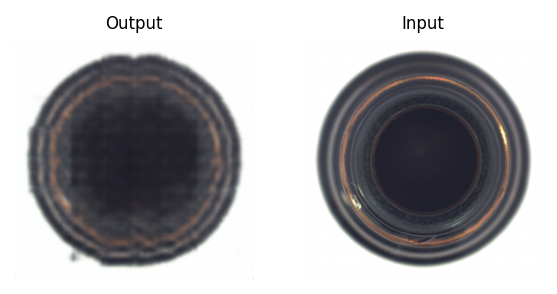

In [68]:
from PIL import Image
import matplotlib.pyplot as plt

i = 47
# 1. Open the image using PIL
#img = train_norm[8][0]
#img = [train0[0].cpu(), test0[0].cpu()]
img = [train0[0].cpu(), train[0]]


# 2. Pass the PIL image directly into Matplotlib
img_to_show1 = img[0].permute(1, 2, 0)
img_to_show2 = img[1].permute(1, 2, 0)

fig, axes = plt.subplots(1, 2, figsize=(4, 2), dpi=150)

# Plot first image (Reconstruction)
axes[0].imshow(img_to_show1)
axes[0].set_title("Output", fontsize=8)
axes[0].axis('off')

# Plot second image (Input / Target)
axes[1].imshow(img_to_show2)
axes[1].set_title("Input", fontsize=8)
axes[1].axis('off')

plt.tight_layout()
plt.show()